In [135]:
import json

import cv2
import numpy as np
import matplotlib.pyplot as plt

from fisheye_camera import CameraCalibrationParameters
from detection_area import CameraConfiguration, DetectionArea

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


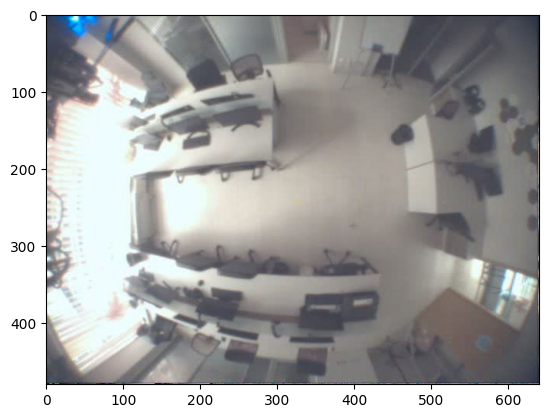

In [136]:
img = cv2.cvtColor(cv2.imread('example.jpg'), cv2.COLOR_BGR2RGB)
plt.imshow(img)

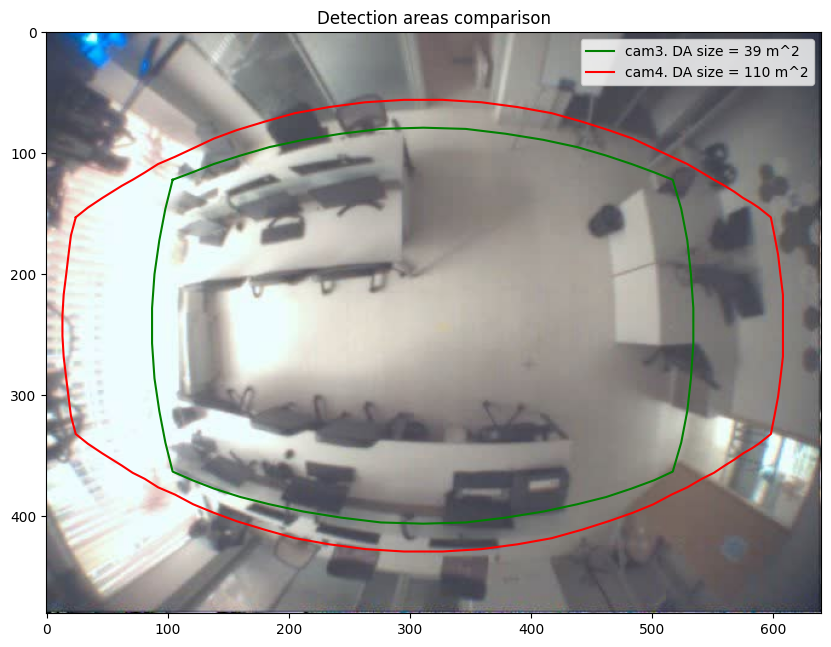

In [140]:
plt.figure(figsize=(10, 10))

H = 270

with open("camera_calibration/params/pg2-video_20241119142311.json", "rt") as f:
    data = json.load(f)

calibration_params = CameraCalibrationParameters(
    data["CX"],
    data["CY"],
    data["FX"],
    data["FY"],
    *data["D"]
)

cam_config = CameraConfiguration(
    calibration_params,
    135, #data["FOV_X"],
    109, #data["FOV_Y"],
    H,
    *data["DIM"]
)

da_cam3 = DetectionArea(cam_config)

poly = np.array(da_cam3.polygon_in_pixels())

 
plt.imshow(img)
plt.plot(poly[:, 0], poly[:, 1], 'g-', label=f"cam3. DA size = {round(da_cam3.m_rectangle_cm.h * da_cam3.m_rectangle_cm.w / 10000)} m^2")

cam_config = CameraConfiguration(
    calibration_params,
    data["FOV_X"],
    data["FOV_Y"],
    H,
    *data["DIM"]
)

da_cam3 = DetectionArea(cam_config)

poly = np.array(da_cam3.polygon_in_pixels())

plt.plot(poly[:, 0], poly[:, 1], 'r-', label=f"cam4. DA size = {round(da_cam3.m_rectangle_cm.h * da_cam3.m_rectangle_cm.w / 10000)} m^2")

plt.ylim(480, 0)

plt.title("Detection areas comparison")
plt.legend()